In [18]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 

from sklearn.model_selection import TimeSeriesSplit, GridSearchCV 
from sklearn.pipeline import Pipeline 
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score 

from skopt import BayesSearchCV
from skopt.space import Real, Categorical 
import warnings 
warnings.filterwarnings('ignore')

# Load & Cleaning Data

In [3]:
df = pd.read_excel("/Users/asyzyni/Desktop/Data Rapih Capstone/Data Capstone Fix BGt.xlsx")
df.head()

,Tanggal,Kelembapan Rata-Rata Udara Harian (%),Temperatur Rata-Rata Harian,Temperatur Maksimum Harian,Temperature Minimum Harian,Angin Rata-Rata Harian (Knot),Curah Hujan,Penyinaran Harian (%),Penguapan Harian (mm),Tekanan Udara Harian (mb)
0,2018-01-01,87.0,27.2,30.2,22.7,2.5,0,0.0,5.4,1008.0
1,2018-01-02,85.0,27.3,32.4,24.2,2.7,0,100.0,3.5,1008.5
2,2018-01-03,77.0,29.7,32.6,24.6,2.1,0,65.0,4.0,1009.3
3,2018-01-04,80.0,28.3,31.8,25.2,2.3,0,43.8,5.2,1009.1
4,2018-01-05,81.0,28.4,32.2,24.3,2.4,6,56.3,2.8,1009.8


mengubah nilai TTU 

In [4]:
df['Curah Hujan'] = df['Curah Hujan'].replace('TTU', 0.01)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1826 entries, 0 to 1825
Data columns (total 10 columns):
 #   Column                                 Non-Null Count  Dtype         
---  ------                                 --------------  -----         
 0   Tanggal                                1826 non-null   datetime64[ns]
 1   Kelembapan Rata-Rata Udara Harian (%)  1826 non-null   float64       
 2   Temperatur Rata-Rata Harian            1826 non-null   float64       
 3   Temperatur Maksimum Harian             1826 non-null   float64       
 4   Temperature Minimum Harian             1826 non-null   float64       
 5   Angin Rata-Rata Harian (Knot)          1826 non-null   float64       
 6   Curah Hujan                            1826 non-null   float64       
 7   Penyinaran Harian (%)                  1826 non-null   float64       
 8   Penguapan Harian (mm)                  1826 non-null   float64       
 9   Tekanan Udara Harian (mb)              1826 non-null   float64 

# EDA

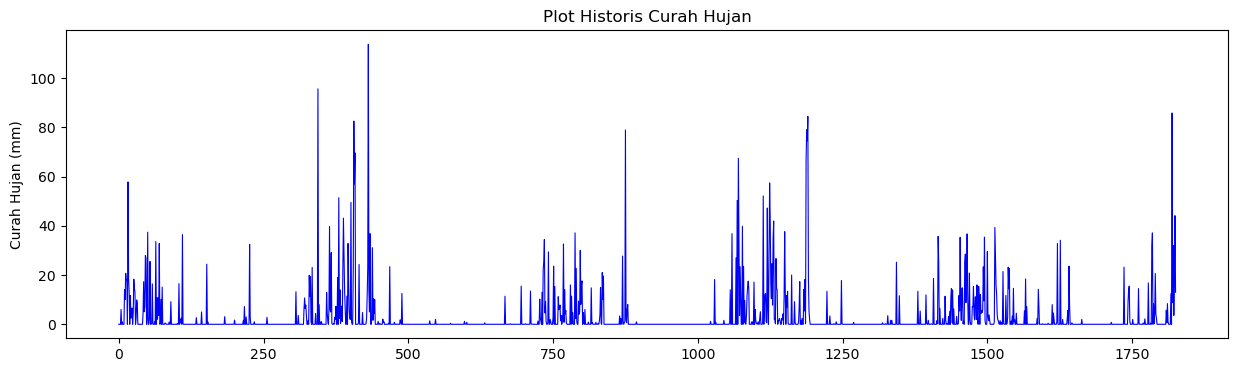

In [6]:
plt.figure(figsize=(15, 4))
plt.plot(df.index, df['Curah Hujan'], color='blue', linewidth=0.8)
plt.title('Plot Historis Curah Hujan')
plt.ylabel('Curah Hujan (mm)')
plt.show()

In [7]:
df['Tanggal'] = pd.to_datetime(df['Tanggal'])
df.set_index('Tanggal', inplace=True)

# Feature Engineering

In [8]:
# Membuat Lag Features (Fitur nilai hari-hari sebelumnya)
df['Curah_Hujan_Lag1'] = df['Curah Hujan'].shift(1)
df['Curah_Hujan_Lag2'] = df['Curah Hujan'].shift(2)
df['Kelembapan_Lag1'] = df['Kelembapan Rata-Rata Udara Harian (%)'].shift(1)

In [9]:
# Membuat Rolling Mean (Rata-rata pergerakan 3 hari terakhir dari curah hujan)
df['Rolling_Mean_3Days'] = df['Curah Hujan'].shift(1).rolling(window=3).mean()

In [10]:
df['Bulan'] = df.index.month
df['Bulan_Sin'] = np.sin(2 * np.pi * df['Bulan'] / 12)
df['Bulan_Cos'] = np.cos(2 * np.pi * df['Bulan'] / 12)

In [11]:
df.dropna(inplace=True)

In [12]:
X = df.drop(columns=['Curah Hujan', 'Bulan'])
y = df['Curah Hujan']

# Split Data Time Series 

In [13]:
train_size = int(len(df) * 0.8)

In [14]:
X_train, X_test = X.iloc[:train_size], X.iloc[train_size:]
y_train, y_test = y.iloc[:train_size], y.iloc[train_size:]

print(f"Jumlah Data Latih (Train): {len(X_train)}")
print(f"Jumlah Data Uji (Test)   : {len(X_test)}")

Jumlah Data Latih (Train): 1458
Jumlah Data Uji (Test)   : 365


# Pipeline & Hyperparameter Tuning SVR 

In [15]:
pipeline = Pipeline([
    ('scaler', StandardScaler()), 
    ('svr', SVR())
])

In [19]:
# tnetukan parameter yang inigin di uji menggunakan bayesian optimization 
search_spaces = {
    'svr__kernel' : Categorical(['rbf']), 
    'svr__C' : Real(0.1, 100.0, prior='log-uniform'), 
    'svr__gamma' : Real(0.001, 1.0, prior='log-uniform'), 
    'svr__epsilon' : Real(0.001, 1.0, prior='log-uniform')
}


In [20]:
tscv = TimeSeriesSplit(n_splits=3)

In [22]:
bayes_search = BayesSearchCV(
    estimator=pipeline, 
    search_spaces=search_spaces, 
    n_iter=30, 
    cv=tscv, 
    scoring='neg_mean_absolute_error', 
    n_jobs=-1,
    random_state = 42, 
    verbose=1
)

In [23]:
bayes_search.fit(X_train, y_train)

Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fi

BayesSearchCV(cv=TimeSeriesSplit(gap=0, max_train_size=None, n_splits=3, test_size=None),
              estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                        ('svr', SVR())]),
              n_iter=30, n_jobs=-1, random_state=42,
              scoring='neg_mean_absolute_error',
              search_spaces={'svr__C': Real(low=0.1, high=100.0, prior='log-uniform', transform='normalize'),
                             'svr__epsilon': Real(low=0.001, high=1.0, prior='log-uniform', transform='normalize'),
                             'svr__gamma': Real(low=0.001, high=1.0, prior='log-uniform', transform='normalize'),
                             'svr__kernel': Categorical(categories=('rbf',), prior=None)},
              verbose=1)

In [24]:
best_model = bayes_search.best_estimator_
print(f"\n Parameter terbaik dari bayesian optimization:\n {bayes_search.best_params_}")


 Parameter terbaik dari bayesian optimization:
 OrderedDict([('svr__C', 19.799860466309713), ('svr__epsilon', 0.001), ('svr__gamma', 0.02906118571321077), ('svr__kernel', 'rbf')])


# Prediksi dan Evaluasi 

In [25]:
y_pred = best_model.predict(X_test)

y_pred = np.maximum(y_pred, 0)

In [26]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)


In [27]:
print("\n--- Hasil Evaluasi pada Data Test ---")
print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R-Squared : {r2:.2f}")


--- Hasil Evaluasi pada Data Test ---
MAE  : 2.74
RMSE : 6.96
R-Squared : 0.37


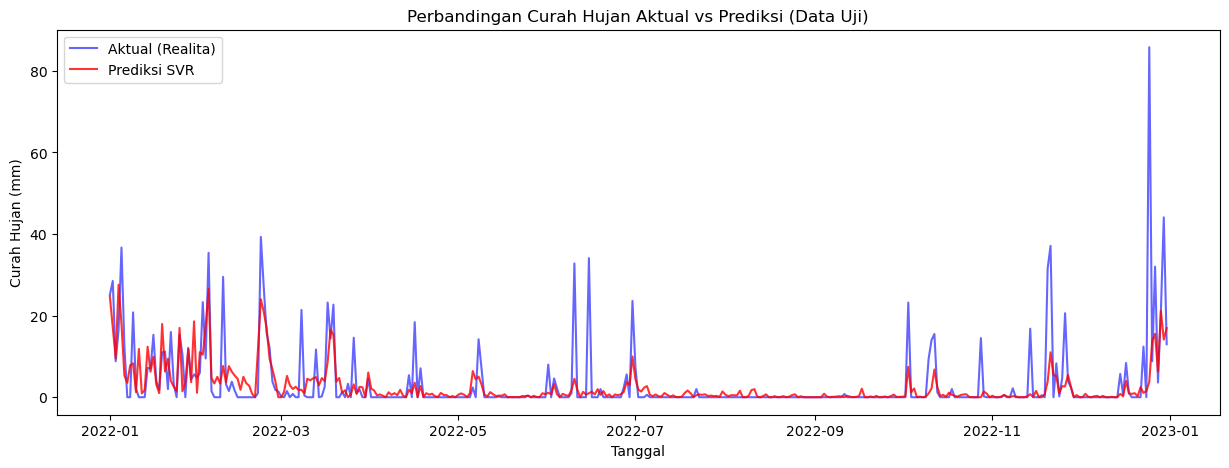

In [28]:
# Visualisasi Hasil Prediksi vs Aktual
plt.figure(figsize=(15, 5))
plt.plot(y_test.index, y_test.values, label='Aktual (Realita)', color='blue', alpha=0.6)
plt.plot(y_test.index, y_pred, label='Prediksi SVR', color='red', alpha=0.8)
plt.title('Perbandingan Curah Hujan Aktual vs Prediksi (Data Uji)')
plt.ylabel('Curah Hujan (mm)')
plt.xlabel('Tanggal')
plt.legend()
plt.show()


diawal, model masih sesuai untuk mengenali pola dari curah hujan. namun, model masih kurang untuk mempelajari peningkatan curah hujan yang tiba-tiba pada setiap waktu